# Question 2 - Motion or Memory?

Run all cells in Colab with a GPU runtime. Results, figures and answers are in the report, `assignment_02/Assignment2_Report.pdf`.

In [4]:
# Fetch the implementation from GitHub (equivalent to !git clone / %cd).
import importlib.util
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
REPOSITORY_URL = "https://github.com/rana-taqveem/msai_dl4stg.git"
REPO_ROOT = Path("/content/msai_dl4stg")
UPDATE_REPOSITORY = True
BOOTSTRAP_CODE_DIR = None

if IN_COLAB:
    if not REPO_ROOT.exists():
        subprocess.check_call(["git", "clone", REPOSITORY_URL, str(REPO_ROOT)])
    elif not (REPO_ROOT/".git").is_dir():
        raise RuntimeError(f"{REPO_ROOT} exists but is not a Git checkout. Choose another REPO_ROOT.")
    elif UPDATE_REPOSITORY:
        dirty = subprocess.check_output(["git", "-C", str(REPO_ROOT), "status", "--porcelain"], text=True)
        if dirty.strip():
            raise RuntimeError("The Colab checkout has local edits. Commit/save them, or set UPDATE_REPOSITORY=False to use that checkout unchanged.")
        subprocess.check_call(["git", "-C", str(REPO_ROOT), "pull", "--ff-only"])
    BOOTSTRAP_CODE_DIR = REPO_ROOT/"assignment_02"/"Question2"
    required = ["q2_core.py", "q2_models.py", "q2_data.py", "q2_experiment.py", "q2_figures.py", "q2_report.py"]
    missing = [name for name in required if not (BOOTSTRAP_CODE_DIR/name).exists()]
    if missing:
        raise FileNotFoundError(f"The cloned revision is missing {missing}. Commit and push the Question2 files to GitHub, then rerun this cell.")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "-r", str(REPO_ROOT/"assignment_02"/"requirements.txt")])
    probe = subprocess.run([sys.executable, "-c", "from torchvision.datasets import MovingMNIST"], capture_output=True, text=True)
    if probe.returncode:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--upgrade", "torch", "torchvision"])
    revision = subprocess.check_output(["git", "-C", str(REPO_ROOT), "rev-parse", "--short", "HEAD"], text=True).strip()
    print(f"Code directory: {BOOTSTRAP_CODE_DIR}; Git commit: {revision}")
else:
    print("Local execution: using the project files; no clone needed.")


Code directory: /content/msai_dl4stg/assignment_02/Question2; Git commit: 8b2b0dd


In [5]:
from pathlib import Path
import random

import numpy as np
import torch
import torchvision
from torch.utils.data import DataLoader, Subset

SEED = 0
BATCH_SIZE = 32
NUM_WORKERS = 0  # Reliable in Windows notebooks; avoids dataset worker copies.


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
print(f"PyTorch: {torch.__version__}; torchvision: {torchvision.__version__}")

if not hasattr(torchvision.datasets, "MovingMNIST"):
    raise RuntimeError("This torchvision version lacks MovingMNIST. Upgrade torch and torchvision together.")


import sys

# Override this if your source files are elsewhere (for example a Colab clone).
CODE_DIR_OVERRIDE = None


Device: cuda
PyTorch: 2.11.0+cu130; torchvision: 0.26.0+cu130


In [6]:
# Persistent results and optional persistent dataset cache.
import json
import shutil

USE_GOOGLE_DRIVE = IN_COLAB
CACHE_DATASET_ON_DRIVE = False
DRIVE_RUN_FOLDER = "DL4STG/assignment_02/Question2"

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RUN_DIR = Path("/content/drive/MyDrive") / DRIVE_RUN_FOLDER
else:
    cwd = Path.cwd().resolve()
    if (cwd/"assignment_02"/"Question2").is_dir():
        RUN_DIR = cwd/"assignment_02"/"Question2"
    elif (cwd/"Question2").is_dir():
        RUN_DIR = cwd/"Question2"
    else:
        RUN_DIR = cwd

RUN_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = RUN_DIR/"outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_ROOT = (RUN_DIR/"data") if (not IN_COLAB or CACHE_DATASET_ON_DRIVE) else Path("/content/dl4stg_q2_data")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

code_candidates = ([Path(CODE_DIR_OVERRIDE)] if CODE_DIR_OVERRIDE else [])

if BOOTSTRAP_CODE_DIR is not None:
    code_candidates.append(BOOTSTRAP_CODE_DIR)

code_candidates += [RUN_DIR, Path.cwd()/"assignment_02"/"Question2", Path.cwd()/"Question2", Path.cwd()]
CODE_DIR = next((p.resolve() for p in code_candidates if (p/"q2_core.py").exists()), None)

if CODE_DIR is None:
    raise FileNotFoundError("Run the bootstrap cell, or set CODE_DIR_OVERRIDE to the companion modules folder.")

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

if IN_COLAB:
    # Record the source revision; the code itself is retrieved from Git.
    revision = subprocess.check_output(["git", "-C", str(CODE_DIR), "rev-parse", "HEAD"], text=True).strip()
    (OUTPUT_DIR/"source_revision.json").write_text(json.dumps({
        "repository": REPOSITORY_URL, "commit": revision, "code_directory": str(CODE_DIR)
    }, indent=2), encoding="utf-8")
    # Keep editable notes/configuration and prediction text beside persistent outputs.
    for relative in ("qualitative_notes.json", "selection_review.json", "submission.json",
                     "AI_ASSISTANCE.md", ".gitignore", "predictions/Q2_5.md"):
        source, destination = CODE_DIR/relative, RUN_DIR/relative
        if source.exists() and not destination.exists():
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(source, destination)
    # If you previously cached the dataset, reuse it even in temporary-data mode.
    cached = RUN_DIR/"data/MovingMNIST/mnist_test_seq.npy"
    local = DATA_ROOT/"MovingMNIST/mnist_test_seq.npy"
    if not CACHE_DATASET_ON_DRIVE and cached.exists() and not local.exists():
        print("Copying existing Drive dataset cache to Colab storage...")
        local.parent.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(cached, local)
    print(f"Git revision recorded on Drive: {revision}")

print(f"Dataset: {DATA_ROOT}")
print(f"Persistent results/checkpoints: {OUTPUT_DIR}")
print(f"Implementation source: {CODE_DIR}")


Mounted at /content/drive
Git revision recorded on Drive: 8b2b0dd624fb99bf508252ccd1c38556bf4c2a3d
Dataset: /content/dl4stg_q2_data
Persistent results/checkpoints: /content/drive/MyDrive/DL4STG/assignment_02/Question2/outputs
Implementation source: /content/msai_dl4stg/assignment_02/Question2


### Load videos and split by index

In [7]:
def normalize_video(video):
    return video.to(dtype=torch.float32).div(255.0)


def split_videos(dataset):
    if len(dataset) != 10_000:
        raise ValueError(f"Expected 10,000 complete videos, got {len(dataset)}.")

    return (
        Subset(dataset, range(0, 8_000)),
        Subset(dataset, range(8_000, 9_000)),
        Subset(dataset, range(9_000, 10_000)),
    )


# Verify the official checksum: torchvision otherwise accepts an existing
# filename even when a previous download was interrupted.
from torchvision.datasets.utils import check_integrity, download_url

dataset_file = DATA_ROOT / "MovingMNIST" / "mnist_test_seq.npy"
dataset_md5 = "be083ec986bfe91a449d63653c411eb2"

if not check_integrity(str(dataset_file), dataset_md5):
    print("Downloading a verified copy of Moving MNIST (existing file absent or incomplete).")
    # Use a temporary name; replace the old file only after checksum validation.
    download_url(
        "https://www.cs.toronto.edu/~nitish/unsupervised_video/mnist_test_seq.npy",
        root=str(dataset_file.parent), filename="mnist_test_seq.npy.download",
        md5=dataset_md5,
    )
    dataset_file.with_name("mnist_test_seq.npy.download").replace(dataset_file)

# Load once; subsequent runs reuse the verified file.
mnist_ds = torchvision.datasets.MovingMNIST(
    root=str(DATA_ROOT), split=None, download=True, transform=normalize_video
)
train_mnist_ds, val_mnist_ds, test_mnist_ds = split_videos(mnist_ds)

assert mnist_ds.split is None
assert train_mnist_ds.indices == range(0, 8_000)
assert val_mnist_ds.indices == range(8_000, 9_000)
assert test_mnist_ds.indices == range(9_000, 10_000)

# Check implementation on a training video without inspecting test outcomes.
video = train_mnist_ds[0]
assert tuple(video.shape) == (20, 1, 64, 64)
assert video.dtype == torch.float32
assert torch.isfinite(video).all()
assert 0 <= video.min().item() <= video.max().item() <= 1

print(f"Train: {len(train_mnist_ds)} | Validation: {len(val_mnist_ds)} | Test: {len(test_mnist_ds)}")
print(f"Video shape: {tuple(video.shape)}; dtype: {video.dtype}; range: [{video.min():.3g}, {video.max():.3g}]")


100%|██████████| 819M/819M [00:21<00:00, 38.6MB/s]


Train: 8000 | Validation: 1000 | Test: 1000
Video shape: (20, 1, 64, 64); dtype: torch.float32; range: [0, 1]


In [8]:
loader_options = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
    drop_last=False,  # Include every video, including the final partial test batch.
)

train_loader = DataLoader(
    train_mnist_ds, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_options
)
val_loader = DataLoader(val_mnist_ds, shuffle=False, **loader_options)
test_loader = DataLoader(test_mnist_ds, shuffle=False, **loader_options)

assert len(test_loader.dataset) == 1_000
assert len(test_loader) == 32  # 31 full batches plus 8 videos.
print("Loaders ready. Each batch is a video tensor, not an (image, label) pair.")


Loaders ready. Each batch is a video tensor, not an (image, label) pair.


## Transformations and forecast windows

In [9]:
# Table 1 and every experiment use exactly these shared functions.
from q2_core import mirror, rotate, G, apply_symmetry, inverse_symmetry


In [10]:
from q2_core import allowed_starts, window_frame_numbers, make_window, sample_training_window


### Table 1: transformation and window checks

In [11]:
from IPython.display import Markdown, display


def run_transformation_checks():
    # Restore RNG state so running checks does not alter later training sampling.
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(0)
        x = torch.rand(20, 1, 64, 64)

    p = torch.zeros_like(x)
    p[7, 0, 10, 20] = 1
    rows = []

    for label, lhs, rhs in [
        ("(a) M(M(x)) vs x", mirror(mirror(x)), x),
        ("(b) R^4(x) vs x", rotate(x, 4), x),
        ("(c) MRM(x) vs R^-1(x)", mirror(rotate(mirror(x))), rotate(x, -1)),
    ]:
        difference = (lhs - rhs).abs().max().item()
        equal = torch.equal(lhs, rhs)
        assert difference == 0 and equal, label
        rows.append((label, "0; equal=True", f"{difference:.0f}; equal={equal}"))

    for label, transformed, expected in [
        ("(d) M(p) bright pixel", mirror(p), (7, 10, 43)),
        ("(e) R(p) bright pixel", rotate(p), (7, 43, 10)),
    ]:
        positions = transformed.nonzero()
        assert len(positions) == 1
        frame, channel, row, column = positions[0].tolist()
        actual = (frame, row, column)
        assert channel == 0 and actual == expected, label
        rows.append((label, str(expected), str(actual)))

    frame_ids = torch.arange(1, 21).view(20, 1, 1, 1).expand(20, 1, 64, 64)
    expected_frames = {
        1: ([1, 2, 3, 4, 5], [6, 7, 8, 9, 10]),
        2: ([1, 3, 5, 7, 9], [11, 13, 15, 17, 19]),
        3: ([1, 4, 7, 10, 13], [16, 19]),
    }

    for label, k in zip("fgh", (1, 2, 3)):
        inputs, targets = make_window(frame_ids, t=1, k=k)
        actual = (inputs[:, 0, 0, 0].tolist(), targets[:, 0, 0, 0].tolist())
        assert actual == expected_frames[k]
        expected = f"{expected_frames[k][0]} / {expected_frames[k][1]}"
        rows.append((f"({label}) {k}x input / target frames", expected,
                     f"{actual[0]} / {actual[1]}"))

    # Extra checks on every group inverse and every allowed start.
    for g in G:
        assert torch.equal(inverse_symmetry(apply_symmetry(x, g), g), x)

    assert list(allowed_starts()) == list(range(1, 12))

    for k, last_start in ((1, 14), (2, 8), (3, 2)):
        assert list(allowed_starts(k, True)) == list(range(1, last_start + 1))
        for t in allowed_starts(k, True):
            inputs, targets = make_window(frame_ids, t, k)
            assert len(inputs) == 5 and 2 <= len(targets) <= 5
            assert inputs[:, 0, 0, 0].tolist() == [t + j*k for j in range(5)]
            assert targets[:, 0, 0, 0].tolist() == [t + j*k for j in range(5, 10) if t + j*k <= 20]
            # Spatial transforms must preserve the window's frame ordering.
            for g in G:
                transformed = make_window(apply_symmetry(x, g), t, k)
                original = make_window(x, t, k)
                assert all(torch.equal(a, apply_symmetry(b, g))
                           for a, b in zip(transformed, original))

    return rows


table_1 = run_transformation_checks()
table_1_markdown = (
    "**Table 1. Transformation and window checks.**\n\n"
    "| Check | Expected | Yours |\n|---|---|---|\n"
    + "\n".join("| " + " | ".join(row) + " |" for row in table_1)
)
display(Markdown(table_1_markdown))
print("All transformation and window checks passed.")


# Canonical Table 1 export next to Figure 1 and the other setup evidence.
if "OUTPUT_DIR" in globals():
    import csv
    (OUTPUT_DIR/"setup").mkdir(parents=True, exist_ok=True)
    with (OUTPUT_DIR/"setup"/"table_1.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["Check", "Expected", "Yours"])
        writer.writerows(table_1)


**Table 1. Transformation and window checks.**

| Check | Expected | Yours |
|---|---|---|
| (a) M(M(x)) vs x | 0; equal=True | 0; equal=True |
| (b) R^4(x) vs x | 0; equal=True | 0; equal=True |
| (c) MRM(x) vs R^-1(x) | 0; equal=True | 0; equal=True |
| (d) M(p) bright pixel | (7, 10, 43) | (7, 10, 43) |
| (e) R(p) bright pixel | (7, 43, 10) | (7, 43, 10) |
| (f) 1x input / target frames | [1, 2, 3, 4, 5] / [6, 7, 8, 9, 10] | [1, 2, 3, 4, 5] / [6, 7, 8, 9, 10] |
| (g) 2x input / target frames | [1, 3, 5, 7, 9] / [11, 13, 15, 17, 19] | [1, 3, 5, 7, 9] / [11, 13, 15, 17, 19] |
| (h) 3x input / target frames | [1, 4, 7, 10, 13] / [16, 19] | [1, 4, 7, 10, 13] / [16, 19] |

All transformation and window checks passed.


## Figure 1: motion statistics of the training data

In [12]:
import cv2
import json
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


def estimate_training_flow(videos):
    """Pool prescribed Farneback flow over videos 0-49 and all adjacent pairs."""

    if len(videos) < 50:
        raise ValueError("Figure 1 requires the first 50 training videos.")

    all_directions, all_speeds = [], []
    per_video_kept = []
    pair_count = 0

    for index in range(50):
        video = videos[index]
        if tuple(video.shape) != (20, 1, 64, 64) or video.dtype != torch.float32:
            raise ValueError("Expected normalized float32 videos of shape (20,1,64,64).")
        if not bool(torch.isfinite(video).all()) or not 0 <= video.min() <= video.max() <= 1:
            raise ValueError("Expected finite intensities in [0,1].")
        # Normalized uint8 source values round-trip exactly through this conversion.
        frames = video.detach().cpu().mul(255).round().to(torch.uint8)[:, 0].numpy()
        video_kept = 0
        for s in range(19):
            prev = np.ascontiguousarray(frames[s])
            nxt = np.ascontiguousarray(frames[s + 1])
            flow = cv2.calcOpticalFlowFarneback(
                prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0
            )
            dx, dy = flow[..., 0], flow[..., 1]
            magnitude = np.hypot(dx, dy)
            keep = (prev > 51) & (nxt > 51) & (magnitude > 0.5)
            direction = np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360.0
            all_directions.append(direction)
            all_speeds.append(magnitude[keep])
            video_kept += int(keep.sum())
            pair_count += 1
        per_video_kept.append(video_kept)
        if (index + 1) % 10 == 0:
            print(f"Optical flow: {index + 1}/50 training videos")

    directions = np.concatenate(all_directions)
    speeds = np.concatenate(all_speeds)
    assert pair_count == 950

    if speeds.size == 0:
        raise RuntimeError("No flow estimates passed the assignment's pixel filter.")

    assert directions.shape == speeds.shape
    return directions, speeds, {
        "video_indices": [0, 49], "video_count": 50, "frame_pairs": pair_count,
        "kept_pixels": int(speeds.size), "per_video_kept_pixels": per_video_kept,
        "median_speed_pixels_per_frame": float(np.median(speeds)),
        "opencv_version": cv2.__version__,
        "farneback_parameters": [0.5, 3, 15, 3, 5, 1.2, 0],
        "intensity_uint8_threshold_exclusive": 51,
        "speed_threshold_exclusive": 0.5,
    }


flow_directions, flow_speeds, flow_summary = estimate_training_flow(train_mnist_ds)
print(f"Kept {flow_summary['kept_pixels']:,} pixel observations from 950 frame pairs.")


Optical flow: 10/50 training videos
Optical flow: 20/50 training videos
Optical flow: 30/50 training videos
Optical flow: 40/50 training videos
Optical flow: 50/50 training videos
Kept 103,050 pixel observations from 950 frame pairs.


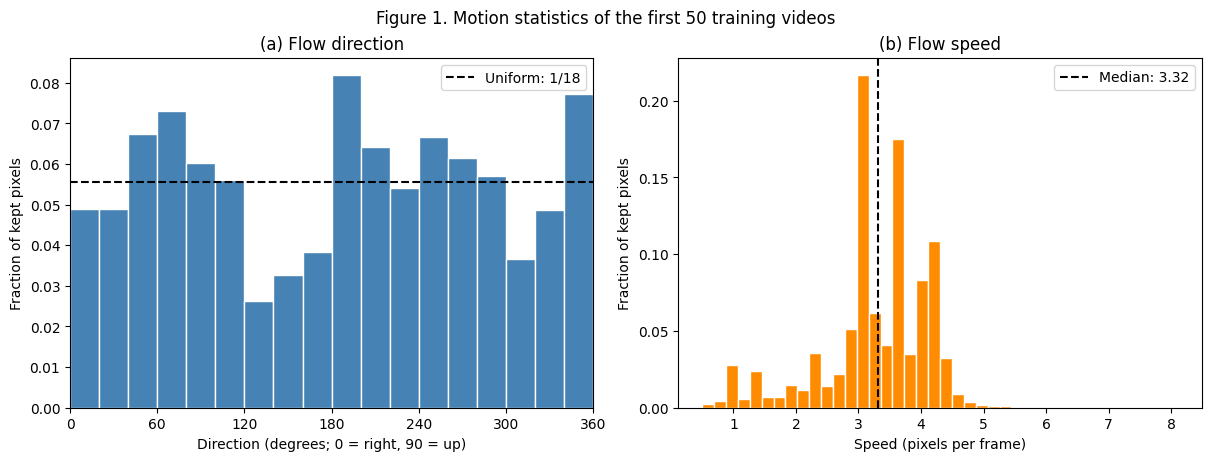

**Figure 1.** Farneback flow from the first 50 training videos, over all 950 adjacent frame pairs. Kept 103,050 pixel observations with intensities >0.2 in both frames and speed >0.5 pixels/frame. Median speed: 3.32 pixels/frame. Both histograms show the fraction of kept pixels per bin; the direction histogram uses 18 bins of 20 degrees.

In [13]:
def plot_motion_statistics(directions, speeds, summary, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    direction_edges = np.arange(0, 361, 20)
    direction_counts, _ = np.histogram(directions, bins=direction_edges)
    direction_fractions = direction_counts / directions.size
    speed_counts, speed_edges = np.histogram(speeds, bins=40)
    speed_fractions = speed_counts / speeds.size
    assert np.isclose(direction_fractions.sum(), 1)
    assert np.isclose(speed_fractions.sum(), 1)
    median = summary["median_speed_pixels_per_frame"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    axes[0].bar(direction_edges[:-1], direction_fractions, width=20,
                align="edge", edgecolor="white", color="steelblue")
    axes[0].axhline(1/18, color="black", linestyle="--", label="Uniform: 1/18")
    axes[0].set(xlim=(0, 360), xticks=np.arange(0, 361, 60),
                xlabel="Direction (degrees; 0 = right, 90 = up)",
                ylabel="Fraction of kept pixels", title="(a) Flow direction")
    axes[0].legend()
    axes[1].bar(speed_edges[:-1], speed_fractions, width=np.diff(speed_edges),
                align="edge", edgecolor="white", color="darkorange")
    axes[1].axvline(median, color="black", linestyle="--", label=f"Median: {median:.3g}")
    axes[1].set(xlabel="Speed (pixels per frame)", ylabel="Fraction of kept pixels",
                title="(b) Flow speed")
    axes[1].legend()
    fig.suptitle("Figure 1. Motion statistics of the first 50 training videos")
    fig.savefig(output_dir / "figure_1.png", dpi=180, bbox_inches="tight")
    plt.show()

    caption = (
        f"**Figure 1.** Farneback flow from the first 50 training videos, over all "
        f"950 adjacent frame pairs. Kept {summary['kept_pixels']:,} pixel observations "
        f"with intensities >0.2 in both frames and speed >0.5 pixels/frame. "
        f"Median speed: {median:.3g} pixels/frame. Both histograms show the fraction "
        "of kept pixels per bin; the direction histogram uses 18 bins of 20 degrees."
    )
    display(Markdown(caption))
    (output_dir / "figure_1_caption.md").write_text(caption, encoding="utf-8")
    (output_dir / "flow_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    np.savez_compressed(output_dir / "flow_histograms.npz",
                        direction_edges=direction_edges, direction_fractions=direction_fractions,
                        speed_edges=speed_edges, speed_fractions=speed_fractions)
    return direction_fractions


direction_fractions = plot_motion_statistics(
    flow_directions, flow_speeds, flow_summary, OUTPUT_DIR / "setup"
)


### Direction histograms under mirror and rotation

In [14]:
direction_edges = np.arange(0, 361, 20)


def direction_histogram(angles):
    counts, _ = np.histogram(angles, bins=direction_edges)
    return counts / counts.sum()


mirrored_fractions = direction_histogram((180.0 - flow_directions) % 360.0)
rotated_fractions = direction_histogram((flow_directions + 90.0) % 360.0)
# Total variation distance: 0 means identical bin fractions, 1 means disjoint.
mirror_tv = float(0.5 * np.abs(direction_fractions - mirrored_fractions).sum())
rotation_tv = float(0.5 * np.abs(direction_fractions - rotated_fractions).sum())
median = flow_summary["median_speed_pixels_per_frame"]
print(f"Direction-bin fractions range from {direction_fractions.min():.3g} to {direction_fractions.max():.3g}; uniform = {1/18:.3g}.")
print(f"Descriptive histogram distance: mirror={mirror_tv:.3g}, rotation={rotation_tv:.3g}.")
print(f"Median speed: {median:.3g} pixels/frame.")
print(f"Reference displacement at 2x: {2*median:.3g}; at 3x: {3*median:.3g} pixels/observed interval.")
print("These multiples are references, not measured fast-sampled optical flow; bounces alter net displacement.")
diagnostics = {"mirror_histogram_total_variation": mirror_tv,
               "rotation_histogram_total_variation": rotation_tv,
               "median_reference_displacements": {str(k): k*median for k in (1, 2, 3)}}
(OUTPUT_DIR / "setup" / "direction_diagnostics.json").write_text(
    json.dumps(diagnostics, indent=2), encoding="utf-8"
)


Direction-bin fractions range from 0.0263 to 0.082; uniform = 0.0556.
Descriptive histogram distance: mirror=0.132, rotation=0.2.
Median speed: 3.32 pixels/frame.
Reference displacement at 2x: 6.64; at 3x: 9.95 pixels/observed interval.
These multiples are references, not measured fast-sampled optical flow; bounces alter net displacement.


247

## Baseline ConvLSTM and training setup

In [15]:
from q2_models import build_model, count_parameters, Symmetrised
from q2_experiment import Experiment, PROTOCOL, Q25
from q2_figures import generate_figures
from q2_report import generate_report

for name in ("A", "B", "C", "D"):
    candidate = build_model(name)
    print(f"{name}: {count_parameters(candidate):,} parameters; reach={candidate.reach_axis} pixels/axis/step; Euclidean max={candidate.reach_euclidean:.3g}")

del candidate
display(PROTOCOL)


A: 480,784 parameters; reach=8 pixels/axis/step; Euclidean max=11.3
B: 480,784 parameters; reach=8 pixels/axis/step; Euclidean max=11.3
C: 480,784 parameters; reach=8 pixels/axis/step; Euclidean max=11.3
D: 480,784 parameters; reach=16 pixels/axis/step; Euclidean max=22.6


{'epochs': 30,
 'batch_size': 32,
 'learning_rate': 0.001,
 'seeds': [0, 1],
 'training_videos': 8000,
 'test_videos': 1000,
 'rollout_steps': 9,
 'version': 1}

### Execution controls

In [16]:
RUN_FULL_EXPERIMENTS = IN_COLAB  # Colab: run all stages; local: setup only by default.
EXPORT_FINAL_PDF = False


def prepare_prediction_repository():
    import subprocess

    def git(*args, check=True):
        return subprocess.run(["git", "-C", str(RUN_DIR), *args], check=check,
                              text=True, capture_output=True)

    if git("rev-parse", "--show-toplevel", check=False).returncode != 0:
        git("init")

    for key, fallback in (("user.name", "DL4STG experiment"), ("user.email", "experiment@localhost")):
        if git("config", "--get", key, check=False).returncode != 0:
            git("config", "--local", key, fallback)


if RUN_FULL_EXPERIMENTS and IN_COLAB and DEVICE.type != "cuda":
    raise RuntimeError("Select Runtime > Change runtime type > GPU, reconnect and rerun. For setup only, set RUN_FULL_EXPERIMENTS=False.")

experiment = Experiment(RUN_DIR, mnist_ds, DEVICE)

if RUN_FULL_EXPERIMENTS:
    prepare_prediction_repository()

print(f"Full experiments enabled: {RUN_FULL_EXPERIMENTS}; device: {DEVICE}")


Full experiments enabled: True; device: cuda


### Train model A

In [17]:
if RUN_FULL_EXPERIMENTS:
    experiment.baseline()
else:
    print("Baseline training pending. Enable full experiments to run/resume both seeds.")


Blank seed 0: E5=0.0425636
Copy-last seed 0: E5=0.0640822
A seed=0 epoch=1/30 train=0.0460684 val=0.0393227 seconds=13.6
A seed=0 epoch=2/30 train=0.0396788 val=0.0385373 seconds=11.9
A seed=0 epoch=3/30 train=0.0386669 val=0.0373225 seconds=11.5
A seed=0 epoch=4/30 train=0.0370371 val=0.0353636 seconds=11.6
A seed=0 epoch=5/30 train=0.035135 val=0.0336951 seconds=11.7
A seed=0 epoch=6/30 train=0.0334729 val=0.0324097 seconds=11.8
A seed=0 epoch=7/30 train=0.032126 val=0.031004 seconds=12.0
A seed=0 epoch=8/30 train=0.0311233 val=0.0301613 seconds=12.3
A seed=0 epoch=9/30 train=0.0303044 val=0.0297076 seconds=12.6
A seed=0 epoch=10/30 train=0.0297802 val=0.0295643 seconds=12.7
A seed=0 epoch=11/30 train=0.0292484 val=0.0287082 seconds=12.5
A seed=0 epoch=12/30 train=0.0288906 val=0.0283023 seconds=12.2
A seed=0 epoch=13/30 train=0.028477 val=0.0279881 seconds=12.1
A seed=0 epoch=14/30 train=0.0280772 val=0.0276004 seconds=12.2
A seed=0 epoch=15/30 train=0.0277974 val=0.0273806 seconds=

### Q2.5 prediction (committed before the stress tests)

In [18]:
if RUN_FULL_EXPERIMENTS:
    display(experiment.require_q25())

prediction_file = RUN_DIR/"predictions"/"Q2_5.md"
display(Markdown(prediction_file.read_text(encoding="utf-8") if prediction_file.exists() else Q25))


{'question': 'Q2_5',
 'commit': 'c3910e60c536719be346ddf9a05d1f54d4848271',
 'sha256': '63b9cedda64b8e396a48c991a20438609fa779a18b2a748113c40ec4ffec8af8',
 'verified_before_stage_utc': '2026-10-28T05:48:27.874657+00:00',
 'content_sha256': 'e0fc3422035ea5eb61df3d8dee103170e5d6d44f2690575941e69c1c63dc0ebf'}

# Q2_5: pre-experiment prediction

I predict that model A will not be exactly consistent under either mirror or rotation, with rotation likely causing a larger accuracy loss because it changes digit appearance more strongly. Figure 1 shows motion in every direction bin, although unequal frequencies and flow bias prevent assuming exact motion symmetry. I expect 2x to degrade prediction and 3x to be particularly difficult: the median displacement references are 6.64 and 9.95 pixels per observed interval, while the longest one-step path in A spans 8 original pixels; reach is a bound, not a guarantee of reliable tracking.


## Testing the baseline (Tables 3-4, Figures 2-5)

In [19]:
if RUN_FULL_EXPERIMENTS:
    experiment.stress()
    generate_figures(experiment)
else:
    print("Stress tests pending final-epoch A checkpoints and committed Q2.5.")


Saved Figures 2-5 and GIFs.


## What can data fix? Q2.11 prediction, then models B-D

In [20]:
if RUN_FULL_EXPERIMENTS:
    display(experiment.require_q211())
    display(Markdown((RUN_DIR/"predictions"/"Q2_11.md").read_text(encoding="utf-8")))
    experiment.improvements()
else:
    print("Q2.11 and B-D training wait for baseline evidence; no future result has been assumed.")


{'question': 'Q2_11',
 'commit': '310dcbf1dcca27fdcb80b7b967058ac50ff3f2df',
 'sha256': 'c12898f0b8316b40d517cb83d90689d5058947e0bc961dae50c45d2b8513948a',
 'verified_before_stage_utc': '2026-10-28T05:48:44.266830+00:00',
 'content_sha256': '9d01a7c0253f79638cd38bf1f72f13878274bc73859118378f293fe5fbaef51e'}

# Q2_11: pre-experiment prediction

After observing baseline A mean gaps CM=0.00197, CR=0.00296, and 3x E(2)=0.0514, I predict symmetry-augmented B will reduce orientation-related inconsistency and transformed error, without guaranteeing exact equivariance. I predict speed-augmented C will improve faster-motion prediction but may remain limited at 3x by its 8-pixel per-axis reach. I predict D, with the same speed augmentation and 16-pixel per-axis reach, will improve 3x tracking relative to C, while not guaranteeing mirror or rotation consistency.


B seed=0 epoch=1/30 train=0.0460723 val=0.0393538 seconds=12.6
B seed=0 epoch=2/30 train=0.0397179 val=0.0386623 seconds=12.8
B seed=0 epoch=3/30 train=0.0387315 val=0.0374352 seconds=12.7
B seed=0 epoch=4/30 train=0.0371781 val=0.0355499 seconds=12.6
B seed=0 epoch=5/30 train=0.0352699 val=0.0338031 seconds=12.5
B seed=0 epoch=6/30 train=0.0335427 val=0.03249 seconds=12.5
B seed=0 epoch=7/30 train=0.032237 val=0.031175 seconds=12.5
B seed=0 epoch=8/30 train=0.0312289 val=0.0303362 seconds=12.6
B seed=0 epoch=9/30 train=0.0304842 val=0.0297813 seconds=12.6
B seed=0 epoch=10/30 train=0.0300156 val=0.0296117 seconds=12.6
B seed=0 epoch=11/30 train=0.0294762 val=0.0288831 seconds=12.5
B seed=0 epoch=12/30 train=0.0291013 val=0.0284886 seconds=12.5
B seed=0 epoch=13/30 train=0.0287006 val=0.0284503 seconds=12.5
B seed=0 epoch=14/30 train=0.0282799 val=0.0278421 seconds=12.6
B seed=0 epoch=15/30 train=0.0280404 val=0.0275429 seconds=12.5
B seed=0 epoch=16/30 train=0.0275554 val=0.0272647 se

## Final model: symmetrised D (Table 6, Figure 6)

In [21]:
if RUN_FULL_EXPERIMENTS:
    experiment.final()
    generate_figures(experiment, final=True)
else:
    print("Final comparison pending trained B and D; no retraining is needed for the wrapper.")


sym_B seed 0: E5=0.0230401
sym_B seed 1: E5=0.0210245
sym_D seed 0: E5=0.0286874
sym_D seed 1: E5=0.0293731
Saved final comparison figures.


## Tables and report

In [22]:
status = generate_report(RUN_DIR, pdf=EXPORT_FINAL_PDF)
display(status)

for number in range(2, 7):
    table_file = OUTPUT_DIR/"tables"/f"table_{number}.md"
    if table_file.exists():
        display(Markdown(f"### Table {number}\n\n" + table_file.read_text(encoding="utf-8")))

print(f"Report: {OUTPUT_DIR/'question_2_report.md'}")


{'all_tables_ready': True,
 'figures_ready': True,
 'setup_ready': True,
 'missing_visual_answers': ['Q2.4', 'Q2.7', 'Q2.9', 'Q2.16'],
 'examples_visually_confirmed': False,
 'ready_for_pdf': False}

### Table 2

| Model | MSE1 | MSE2 | MSE3 | MSE4 | MSE5 | E5 | parameters |
| --- | --- | --- | --- | --- | --- | --- | --- |
| A | 0.017 (0.0172, 0.0169) | 0.0205 (0.0206, 0.0204) | 0.0228 (0.0229, 0.0226) | 0.0246 (0.0247, 0.0244) | 0.0262 (0.0264, 0.026) | 0.0222 (0.0224, 0.022) | 480784 (480784, 480784) |
| Blank | 0.0426 | 0.0426 | 0.0426 | 0.0425 | 0.0425 | 0.0426 | 0 |
| Copy-last | 0.0492 | 0.0604 | 0.0669 | 0.0708 | 0.0732 | 0.0641 | 0 |

### Table 3

| Model | E5 | CM | EM | CR | ER |
| --- | --- | --- | --- | --- | --- |
| A | 0.0222 (0.0224, 0.022) | 0.00197 (0.00201, 0.00193) | 0.0229 (0.023, 0.0228) | 0.00296 (0.00315, 0.00277) | 0.0239 (0.024, 0.0238) |
| Blank | 0.0426 | 0 | 0.0426 | 0 | 0.0426 |
| Copy-last | 0.0641 | 0 | 0.0641 | 0 | 0.0641 |

### Table 4

| Model | E2_1x | E2_2x | E2_3x | E5 | E5_2x |
| --- | --- | --- | --- | --- | --- |
| A | 0.0188 (0.0189, 0.0186) | 0.0441 (0.0445, 0.0438) | 0.0514 (0.0525, 0.0502) | 0.0222 (0.0224, 0.022) | 0.0497 (0.0502, 0.0491) |
| Copy-last | 0.0548 | 0.0661 | 0.0703 | 0.0641 | 0.0719 |

### Table 5

| Model | E5 | CM | EM | CR | ER | E2_1x | E2_2x | E2_3x | parameters | train_seconds_per_epoch | inference_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| A | 0.0222 (0.0224, 0.022) | 0.00197 (0.00201, 0.00193) | 0.0229 (0.023, 0.0228) | 0.00296 (0.00315, 0.00277) | 0.0239 (0.024, 0.0238) | 0.0188 (0.0189, 0.0186) | 0.0441 (0.0445, 0.0438) | 0.0514 (0.0525, 0.0502) | 480784 (480784, 480784) | 12.3 (12.3, 12.3) | 0.398 (0.398, 0.399) |
| B | 0.0226 (0.0236, 0.0216) | 0.00108 (9.60e-04, 0.00121) | 0.0226 (0.0235, 0.0217) | 0.00141 (0.00125, 0.00156) | 0.0226 (0.0236, 0.0216) | 0.019 (0.02, 0.0181) | 0.0436 (0.0427, 0.0445) | 0.0493 (0.0489, 0.0497) | 480784 (480784, 480784) | 12.6 (12.6, 12.7) | 0.401 (0.399, 0.402) |
| C | 0.0269 (0.0263, 0.0275) | 0.00135 (0.00122, 0.00149) | 0.0271 (0.0265, 0.0277) | 0.0028 (0.00318, 0.00243) | 0.0281 (0.0275, 0.0287) | 0.0234 (0.0232, 0.0236) | 0.0288 (0.0285, 0.0292) | 0.0333 (0.0331, 0.0334) | 480784 (480784, 480784) | 12.2 (12.3, 12.2) | 0.397 (0.398, 0.397) |
| D | 0.0292 (0.0289, 0.0294) | 5.33e-04 (7.08e-04, 3.57e-04) | 0.0293 (0.029, 0.0295) | 0.00143 (0.00187, 9.87e-04) | 0.0298 (0.0296, 0.0299) | 0.0266 (0.0262, 0.027) | 0.0303 (0.0299, 0.0306) | 0.0335 (0.0334, 0.0336) | 480784 (480784, 480784) | 45.3 (45.3, 45.2) | 0.653 (0.653, 0.653) |

### Table 6

| Model | E5 | CM | EM | CR | ER | E2_1x | E2_2x | E2_3x | parameters | train_seconds_per_epoch | inference_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| sym_B | 0.022 (0.023, 0.021) | 4.24e-17 (3.94e-17, 4.54e-17) | 0.022 (0.023, 0.021) | 4.32e-17 (4.02e-17, 4.62e-17) | 0.022 (0.023, 0.021) | 0.0186 (0.0196, 0.0176) | 0.0427 (0.0421, 0.0433) | 0.0481 (0.0482, 0.048) | 480784 (480784, 480784) | 12.6 (12.6, 12.7) | 3.49 (3.48, 3.5) |
| sym_D | 0.029 (0.0287, 0.0294) | 3.08e-17 (3.41e-17, 2.75e-17) | 0.029 (0.0287, 0.0294) | 3.16e-17 (3.48e-17, 2.83e-17) | 0.029 (0.0287, 0.0294) | 0.0266 (0.0261, 0.027) | 0.0302 (0.0299, 0.0305) | 0.0334 (0.0332, 0.0335) | 480784 (480784, 480784) | 45.3 (45.3, 45.2) | 5.72 (5.76, 5.69) |

Report: /content/drive/MyDrive/DL4STG/assignment_02/Question2/outputs/question_2_report.md
